(85248, 202752)


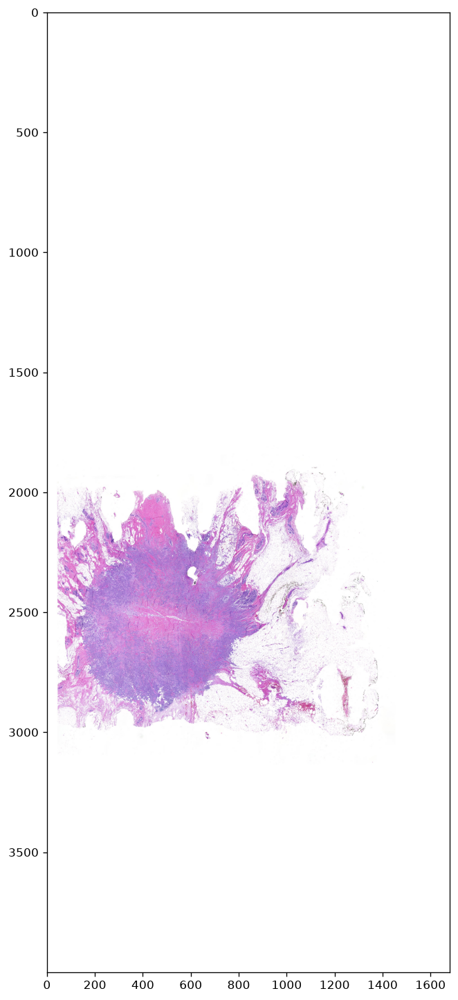

In [1]:
import openslide
import matplotlib.pyplot as plt
import geopandas as gpd
slide = openslide.OpenSlide("C:/Users/Abrah/OneDrive/Documents/Patologia Computacional/sample/01_01_Histological_images/43.mrxs")
print(slide.dimensions)
thumbnail = slide.get_thumbnail((4000, 4000))
plt.figure(figsize=(20, 15), dpi = 120)
plt.imshow(thumbnail)
plt.axis("on")
plt.show()
                                
                            

(85248, 202752)


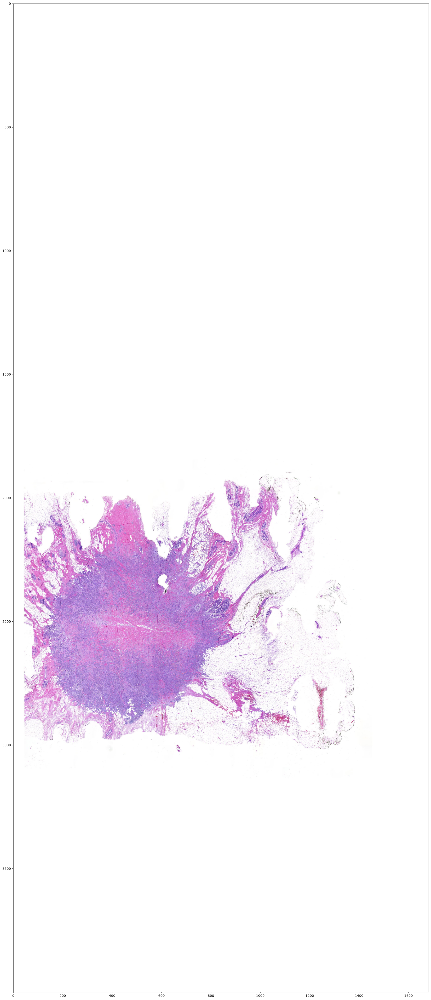

In [2]:
# visualize whole-slide image

slide = openslide.OpenSlide("C:/Users/Abrah/OneDrive/Documents/Patologia Computacional/sample/01_01_Histological_images/43.mrxs")

print(slide.dimensions)

thumbnail = slide.get_thumbnail((4000, 4000))

w, h = thumbnail.size
ratio = h / w

fig, ax = plt.subplots(figsize=(18, 18 * ratio))
ax.imshow(thumbnail)
ax.axis("on")

plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.tight_layout(pad=0)
plt.show()

In [3]:
import openslide
import matplotlib.pyplot as plt

slide = openslide.OpenSlide("C:/Users/Abrah/OneDrive/Documents/Patologia Computacional/sample/01_01_Histological_images/43.mrxs")
print(slide.dimensions)
print(slide.level_dimensions)  # Ver los niveles de resolución disponibles
print(slide.level_downsamples)  # Ver los factores de reducción de cada nivel

(85248, 202752)
((85248, 202752), (42624, 101376), (21312, 50688), (10656, 25344), (5328, 12672), (2664, 6336), (1332, 3168), (666, 1584), (333, 792), (166, 396))
(1.0, 2.0, 4.0, 8.0, 16.0, 32.0, 64.0, 128.0, 256.0, 512.0)


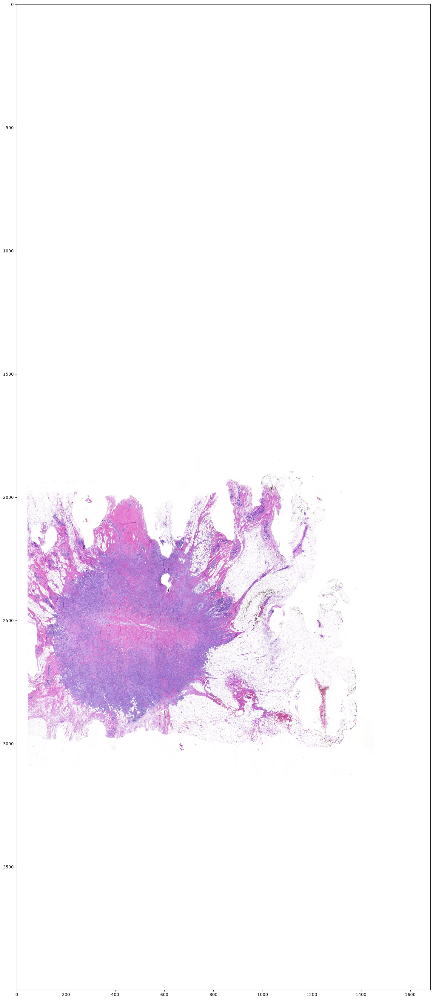

In [4]:
thumbnail = slide.get_thumbnail((4000, 4000))
w, h = thumbnail.size
ratio = h / w

fig, ax = plt.subplots(figsize=(18, 18 * ratio))
ax.imshow(thumbnail)
ax.axis("on")
plt.show()

In [5]:
slide_w, slide_h = slide.dimensions
thumb_w, thumb_h = thumbnail.size

scale_x = slide_w / thumb_w
scale_y = slide_h / thumb_h
print(f"Escala: x={scale_x:.2f}, y={scale_y:.2f}")

# Coordenadas del tumor en la miniatura
x_min_thumb, x_max_thumb = 200, 600
y_min_thumb, y_max_thumb = 2250, 2750

# Convertir al espacio del slide
x_min = int(x_min_thumb * scale_x)
x_max = int(x_max_thumb * scale_x)
y_min = int(y_min_thumb * scale_y)
y_max = int(y_max_thumb * scale_y)
print(f"ROI en slide: x=[{x_min}, {x_max}], y=[{y_min}, {y_max}]")

Escala: x=50.68, y=50.69
ROI en slide: x=[10136, 30409], y=[114048, 139392]


In [6]:
#verificando dimensiones reales
print(f"Dimensiones del slide (w, h): {slide.dimensions}")
print(f"Dimensiones de la miniatura (w, h): {thumbnail.size}")
print(f"Niveles disponibles: {slide.level_dimensions}")

Dimensiones del slide (w, h): (85248, 202752)
Dimensiones de la miniatura (w, h): (1682, 4000)
Niveles disponibles: ((85248, 202752), (42624, 101376), (21312, 50688), (10656, 25344), (5328, 12672), (2664, 6336), (1332, 3168), (666, 1584), (333, 792), (166, 396))


In [7]:
#Extraccion de ROI a menor resolucion de forma robusta
from openslide.deepzoom import DeepZoomGenerator

dz = DeepZoomGenerator(slide, tile_size=256, overlap=0, limit_bounds=False)
print(f"Niveles del DeepZoom: {dz.level_count}")
print(f"Dimensiones por nivel: {dz.level_dimensions}")

Niveles del DeepZoom: 19
Dimensiones por nivel: ((1, 1), (1, 2), (2, 4), (3, 7), (6, 13), (11, 25), (21, 50), (42, 99), (84, 198), (167, 396), (333, 792), (666, 1584), (1332, 3168), (2664, 6336), (5328, 12672), (10656, 25344), (21312, 50688), (42624, 101376), (85248, 202752))


ROI en slide (nivel 0): x=[10136, 30409], y=[114048, 139392]
region_w, region_h: 20273, 25344
ROI extraída: (2534, 3168)


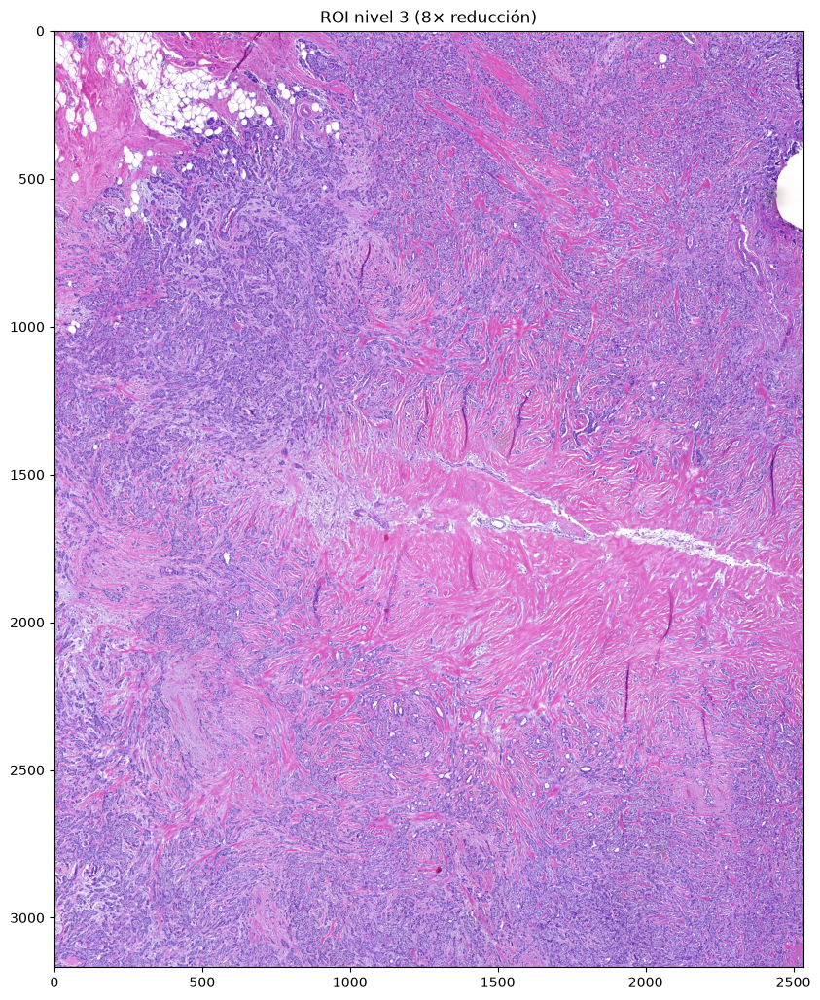

In [8]:
# Coordenadas del tumor en la miniatura
x_min_thumb, x_max_thumb = 200, 600
y_min_thumb, y_max_thumb = 2250, 2750

# Factores de escala
slide_w, slide_h = slide.dimensions
thumb_w, thumb_h = thumbnail.size
scale_x = slide_w / thumb_w
scale_y = slide_h / thumb_h

# Coordenadas en el espacio del slide (nivel 0)
x_min = int(x_min_thumb * scale_x)
x_max = int(x_max_thumb * scale_x)
y_min = int(y_min_thumb * scale_y)
y_max = int(y_max_thumb * scale_y)

# Tamaño de la ROI en el espacio del nivel 0
region_w = x_max - x_min
region_h = y_max - y_min

print(f"ROI en slide (nivel 0): x=[{x_min}, {x_max}], y=[{y_min}, {y_max}]")
print(f"region_w, region_h: {region_w}, {region_h}")

#Verificacion visual inmediada

level = 3  # downsample 8×
factor = int(slide.level_downsamples[level])

region = slide.read_region(
    (x_min, y_min),
    level,
    (int(region_w / factor), int(region_h / factor))
).convert("RGB")

print(f"ROI extraída: {region.size}")

plt.figure(figsize=(10, 10 * region.size[1] / region.size[0]))
plt.imshow(region)
plt.title(f"ROI nivel {level} ({factor}× reducción)")
plt.axis("on")
plt.show()

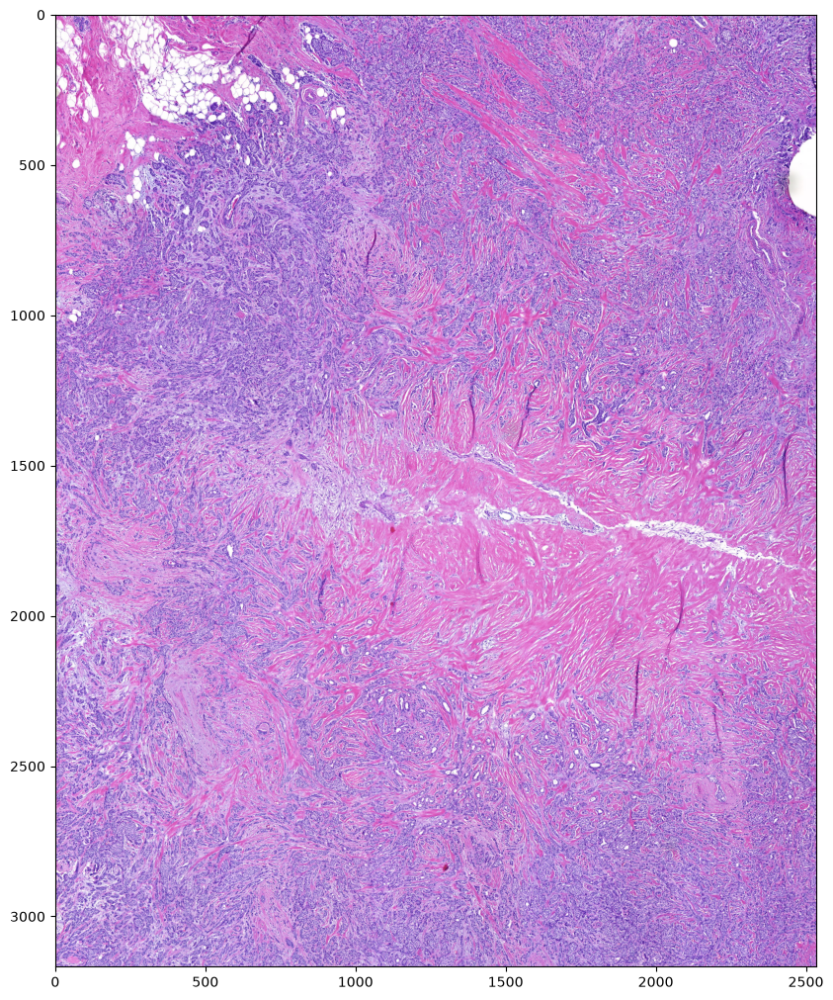

In [9]:
#Flujo limpio
level = 3
factor = int(slide.level_downsamples[level])
region = slide.read_region(
    (x_min, y_min), level,
    (int(region_w / factor), int(region_h / factor))
).convert("RGB")

plt.figure(figsize=(10, 10 * region.size[1] / region.size[0]))
plt.imshow(region)
plt.axis("on")
plt.show()

In [10]:
# Ver qué variables existen en el kernel actual
%who


DeepZoomGenerator	 ax	 dz	 factor	 fig	 gpd	 h	 level	 openslide	 
plt	 ratio	 region	 region_h	 region_w	 scale_x	 scale_y	 slide	 slide_h	 
slide_w	 thumb_h	 thumb_w	 thumbnail	 w	 x_max	 x_max_thumb	 x_min	 x_min_thumb	 
y_max	 y_max_thumb	 y_min	 y_min_thumb	 


In [11]:
#Verificar necesario para parches
for var in ['slide', 'x_min', 'x_max', 'y_min', 'y_max', 'level', 'factor', 'patch_size']:
    print(f"{var}: {'✓' if var in dir() else '✗'}")

    patch_size = 256

slide: ✓
x_min: ✓
x_max: ✓
y_min: ✓
y_max: ✓
level: ✓
factor: ✓
patch_size: ✓


In [12]:
import numpy as np

patches = []
for y in range(y_min, y_max, patch_size * factor):
    for x in range(x_min, x_max, patch_size * factor):
        patch = slide.read_region(
            (x, y), level, (patch_size, patch_size)
        ).convert("RGB")
        patches.append(np.array(patch))

print(f"Parches extraídos: {len(patches)}")
print(f"Forma: {patches[0].shape}, dtype: {patches[0].dtype}")

Parches extraídos: 130
Forma: (256, 256, 3), dtype: uint8


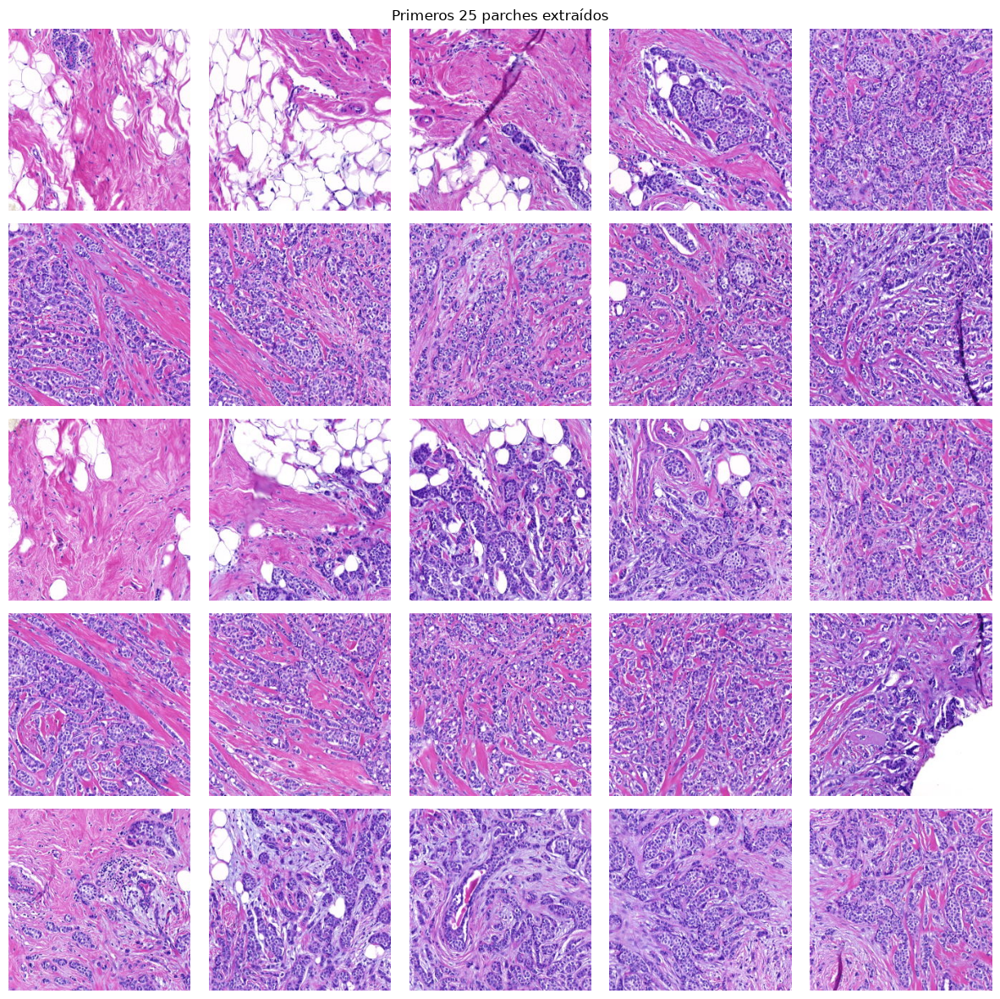

In [13]:
#Verificacion visual de parches
import matplotlib.pyplot as plt

fig, axes = plt.subplots(5, 5, figsize=(12, 12))
for ax, p in zip(axes.flat, patches[:25]):
    ax.imshow(p)
    ax.axis("off")
plt.suptitle("Primeros 25 parches extraídos")
plt.tight_layout()
plt.show()

In [14]:
# Índices que quieres descartar (ajusta según tu revisión visual)
excluir = [0, 1, 2, 10, 11, 12]  # ejemplo

# Filtrar
patches_filtrados = [p for i, p in enumerate(patches) if i not in excluir]

print(f"Originales: {len(patches)}")
print(f"Excluidos: {len(excluir)}")
print(f"Conservados: {len(patches_filtrados)}")

Originales: 130
Excluidos: 6
Conservados: 124


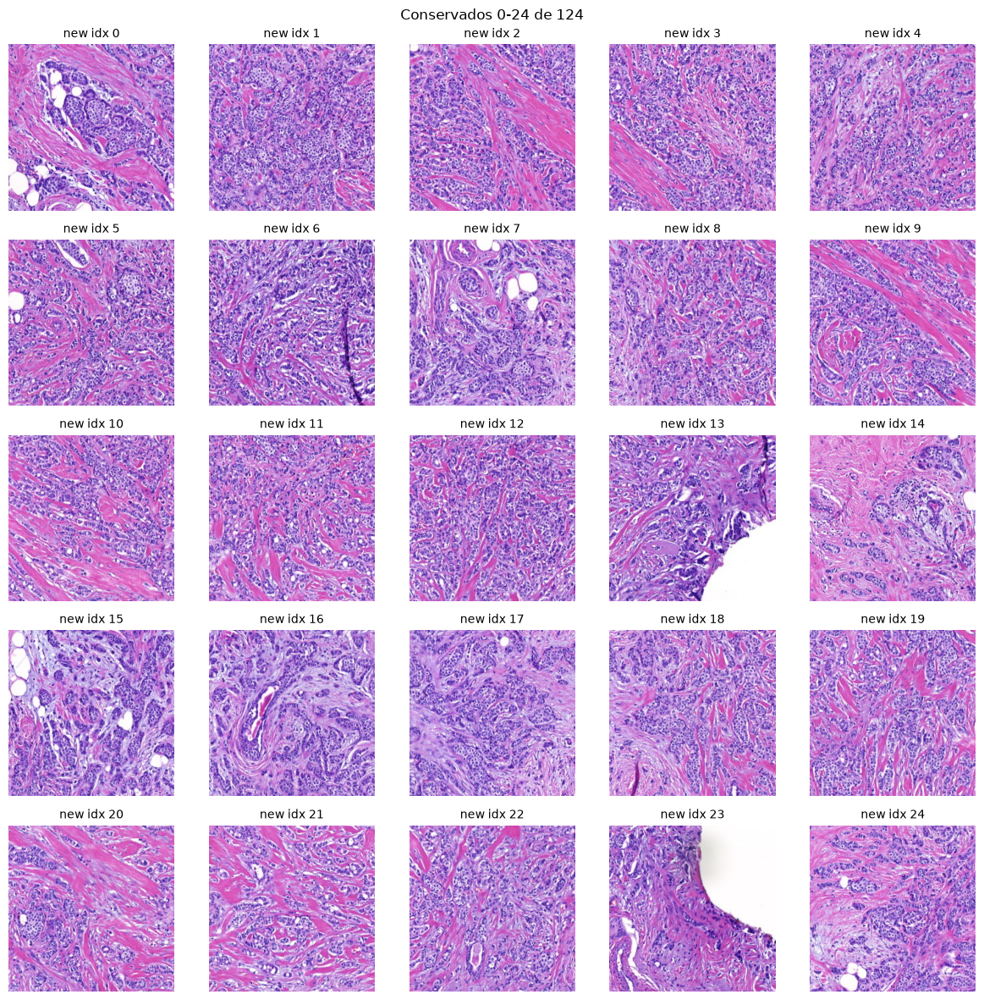

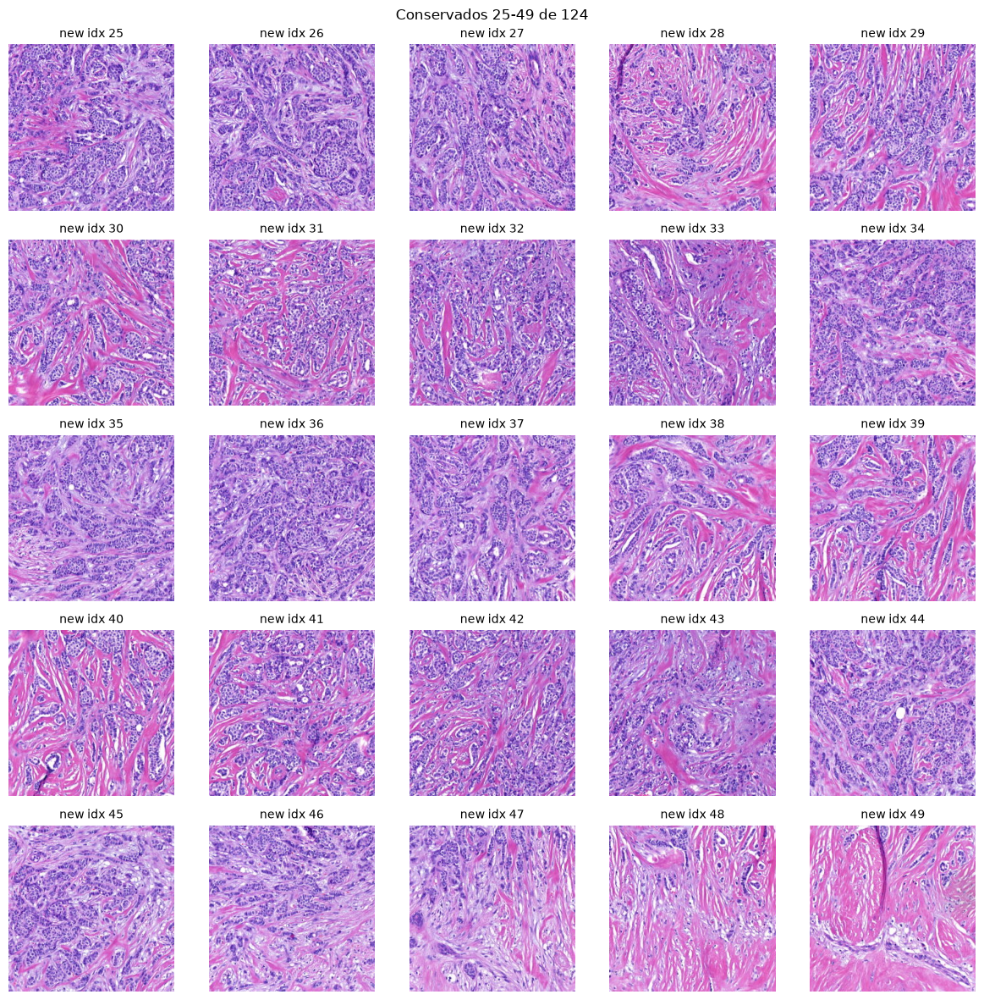

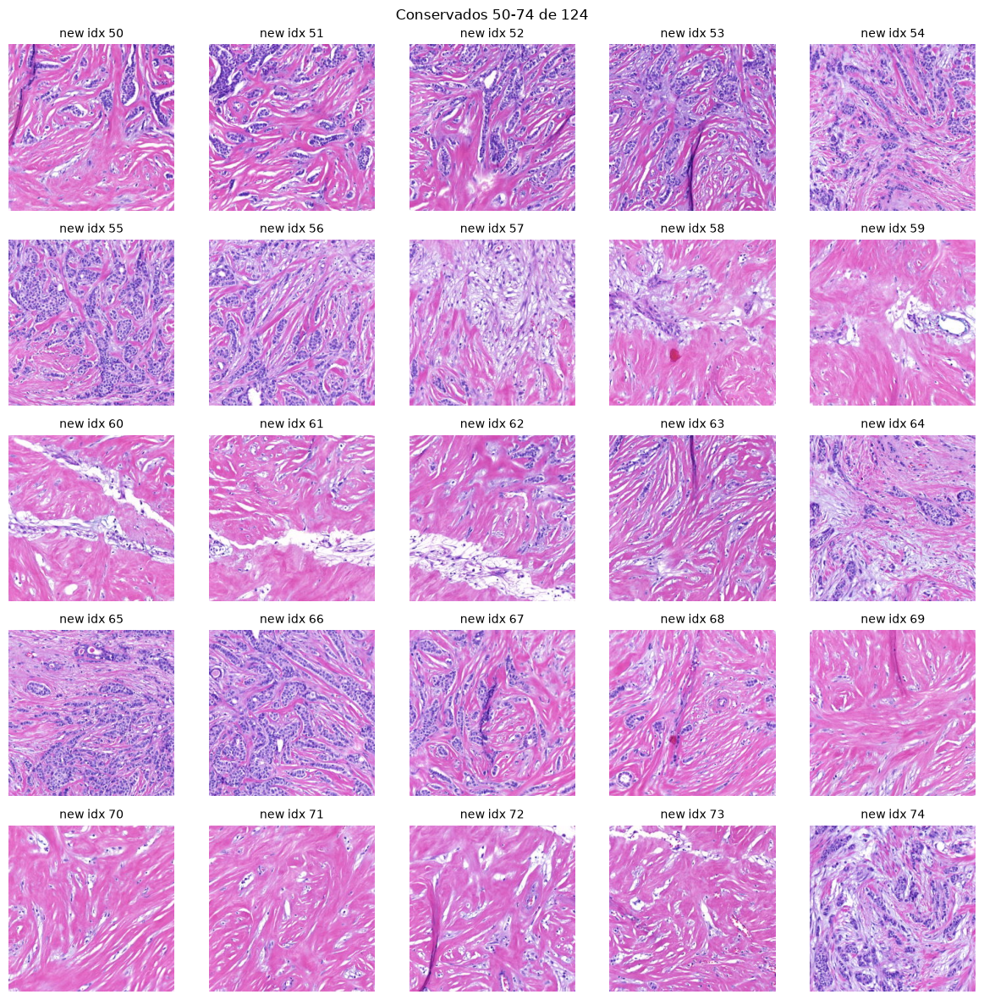

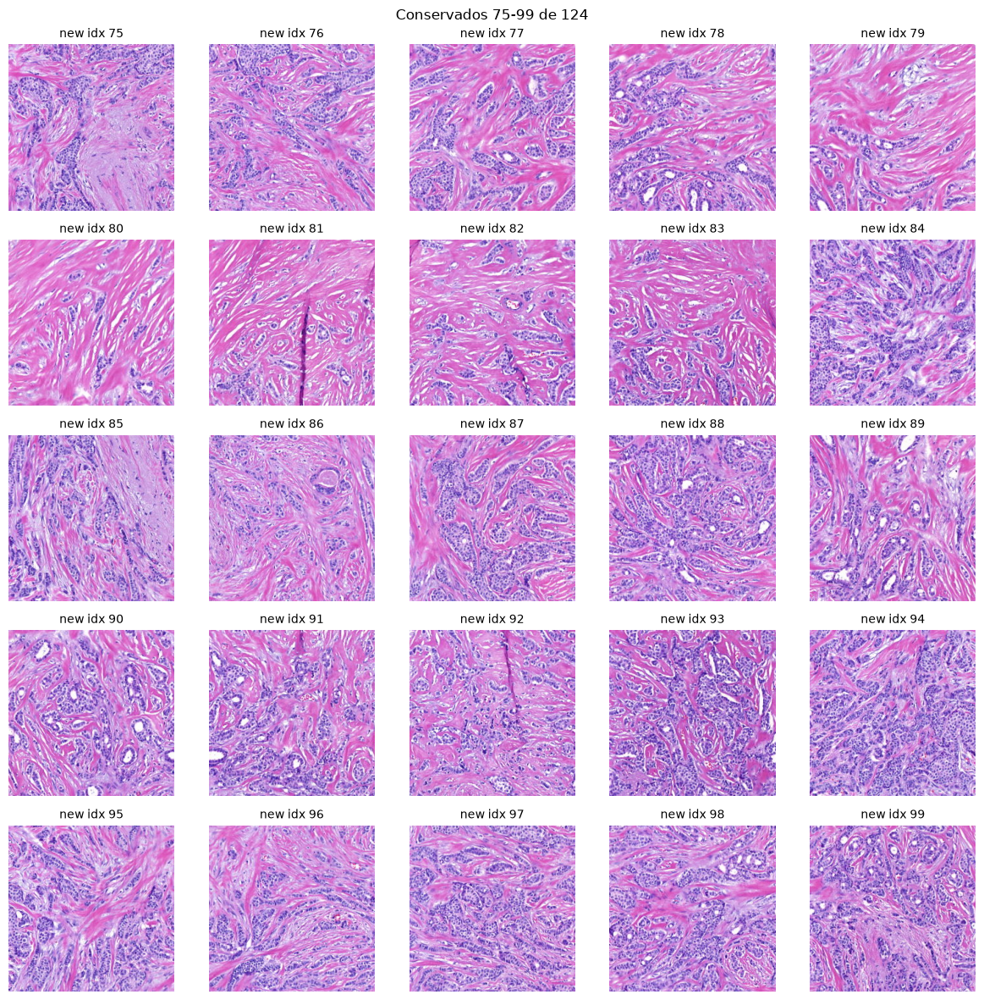

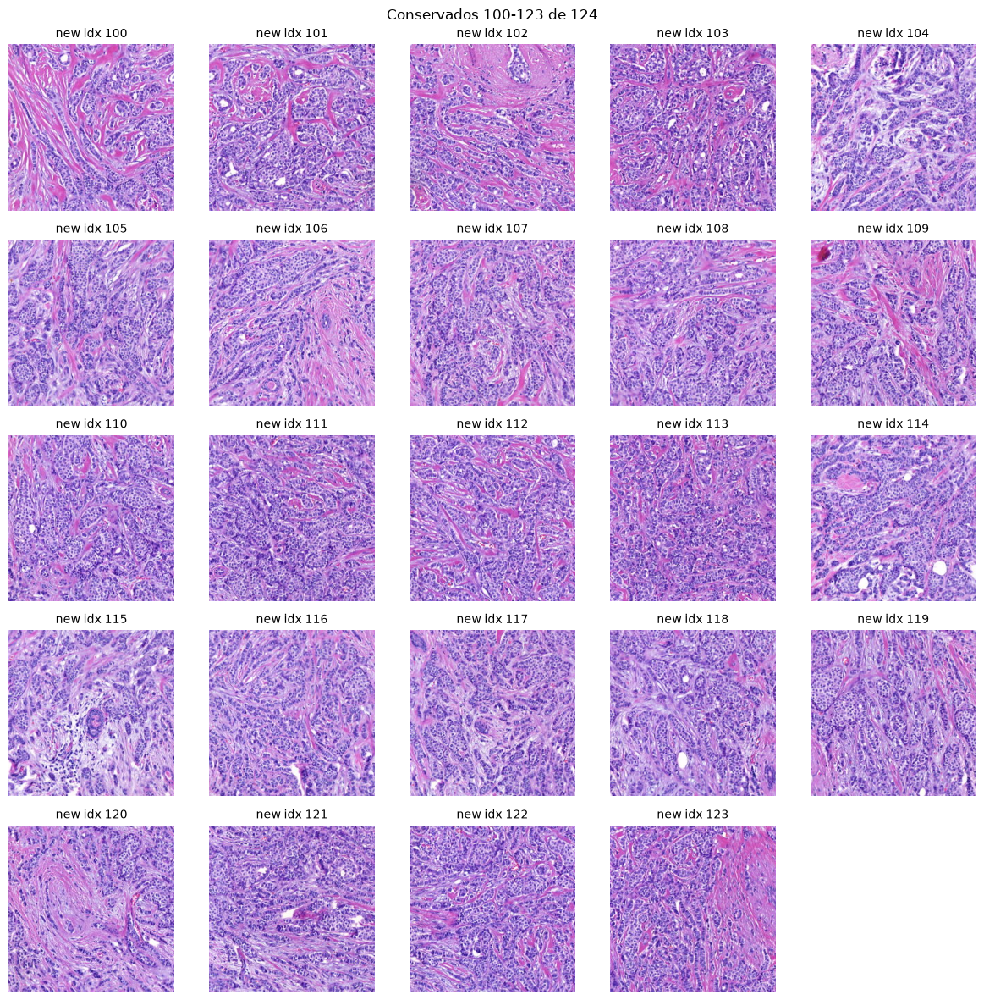

In [15]:
import matplotlib.pyplot as plt

# Cuadrícula de 5×5 por página con cambios y ver todos 
por_pagina = 25
n = len(patches_filtrados)

for inicio in range(0, n, por_pagina):
    fin = min(inicio + por_pagina, n)
    fig, axes = plt.subplots(5, 5, figsize=(12, 12))
    for i, ax in enumerate(axes.flat):
        idx = inicio + i
        if idx < n:
            ax.imshow(patches_filtrados[idx])
            ax.set_title(f"new idx {idx}", fontsize=10)
        ax.axis("off")
    plt.suptitle(f"Conservados {inicio}-{fin-1} de {n}")
    plt.tight_layout()
    plt.show()

In [16]:
#verificar magnificacion
print("Magnificación objetivo:", slide.properties.get('openslide.objective-power'))
print("MPP (micras por píxel):", slide.properties.get('openslide.mpp-x'))

Magnificación objetivo: 20
MPP (micras por píxel): 0.24328396570091901


In [17]:
#Filtrado de tejido sano (Fue un fracaso)

#Definicion Basado en el juicio de intensidad de píxeles (adecuado para fondo blanco)
def is_blank(patch, threshold=0.8):
    gray = np.mean(patch, axis=2) / 255.0
    return np.mean(gray > threshold) > 0.1  # Más del 10% de píxeles son blancos

# Basado en desviación estándar (elimina regiones uniformes, incluido parte del tejido adiposo)
def is_uniform(patch, std_threshold=10):
    return np.std(patch) < std_threshold

In [18]:
import numpy as np

def is_blank(patch, threshold=0.8):
    gray = np.mean(patch, axis=2) / 255.0
    return np.mean(gray > threshold) > 0.9

def is_uniform(patch, std_threshold=10):
    return np.std(patch) < std_threshold

# Aplicar a cada parche
blank_flags = [is_blank(p) for p in patches]
uniform_flags = [is_uniform(p) for p in patches]

print(f"Total de parches: {len(patches)}")
print(f"Parches en blanco: {sum(blank_flags)}")
print(f"Parches uniformes: {sum(uniform_flags)}")

# Filtrar: conservar solo los que NO son blancos NI uniformes
patches_ok = [p for p, b, u in zip(patches, blank_flags, uniform_flags) 
              if not b and not u]
print(f"Parches conservados: {len(patches_ok)}")

#Fracasaron los filtros

Total de parches: 130
Parches en blanco: 0
Parches uniformes: 0
Parches conservados: 130


!pip install histolab

#problema de compatibilidad
#Opciones: crear entonrno python 3.11 O usar numpy 1.26.4 en python 3.12 Consultar con doctora

Averiguar en jupyternotebook como genenrar un ambiente de Conda, instalar como primera dependencia histolab.

import histolab
print(histolab.__version__)

#Alterantiva usar histolab para un filtrado mas estricto

from histolab.tiler import GridTiler
from histolab.masks import TissueMask

grid_tiler = GridTiler(
    tile_size=(256, 256),
    level=2,
    check_tissue=True,
    tissue_percent=90.0  # Prueba primero con 90
)

#No se puede instalar histolab actualmente, ver alternativas.


In [19]:
!pip install torch torchvision

In [20]:
#verificacion
import torch
import torchvision
print(torch.__version__)
print(torchvision.__version__)
print("CUDA disponible:", torch.cuda.is_available())

2.14.1+cpu
0.29.1+cpu
CUDA disponible: False


In [21]:

from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms
import os

print("NumPy:", np.__version__)
print("Pillow:", Image.__version__)
print("TorchVision:", __import__("torchvision").__version__)

NumPy: 2.4.6
Pillow: 12.3.0
TorchVision: 0.29.1+cpu


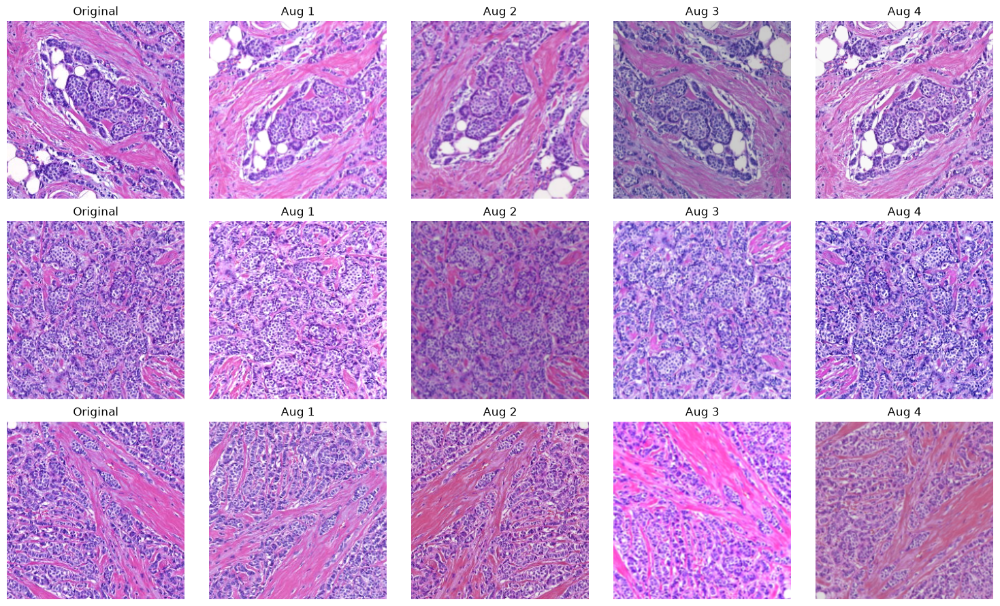

In [22]:
# ============================================================
# Data augmentation para parches de patología de mama
# Rotación en múltiplos de 90° + flip + color jitter + blur
# ============================================================

import random
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms
import torchvision.transforms.functional as F

# --- 1. Transformación personalizada: rotación en múltiplos de 90° ---
class RandomRotation90:
    """Rota la imagen en múltiplos de 90°: 0, 90, 180 o 270."""
    def __init__(self, angles=(0, 90, 180, 270)):
        self.angles = angles
    
    def __call__(self, img):
        angle = random.choice(self.angles)
        return F.rotate(img, angle)

# --- 2. Pipeline de aumentación ---  Se pueden modificar de otro modo??
augment = transforms.Compose([
    RandomRotation90(angles=(0, 90, 180, 270)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0)),
])

# --- 3. Verificación visual ---
fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for i in range(3):
    # Columna 0: original
    axes[i, 0].imshow(patches_filtrados[i])
    axes[i, 0].set_title("Original")
    axes[i, 0].axis("off")
    
    # Columnas 1-4: aumentaciones
    patch_pil = Image.fromarray(patches_filtrados[i])
    for j in range(1, 5):
        aug = augment(patch_pil)
        axes[i, j].imshow(aug)
        axes[i, j].set_title(f"Aug {j}")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [23]:
import os
from PIL import Image

# Asumiendo que ya tienes patches_filtrados y augment definidos
carpeta_salida = "imagenes_aumentadas"
os.makedirs(carpeta_salida, exist_ok=True)

N_AUG = 5  # número de aumentaciones por parche

for i, patch in enumerate(patches_filtrados):
    patch_pil = Image.fromarray(patch)
    
    # Guardar el original (opcional, pero útil para comparar)
    patch_pil.save(f"{carpeta_salida}/parche_{i:04d}_orig.png")
    
    # Guardar las versiones aumentadas
    for j in range(N_AUG):
        aug_img = augment(patch_pil)
        aug_img.save(f"{carpeta_salida}/parche_{i:04d}_aug{j:02d}.png")

print(f"Imágenes guardadas en '{carpeta_salida}/'")

Imágenes guardadas en 'imagenes_aumentadas/'


In [27]:
#donde encontrarlas
import os

# Ruta absoluta de la carpeta
ruta_absoluta = os.path.abspath("imagenes_aumentadas")
print(f"Carpeta: {ruta_absoluta}")

# Cuántos archivos hay
archivos = os.listdir("imagenes_aumentadas")
print(f"Total de archivos: {len(archivos)}")
print(f"Primeros 5: {archivos[:5]}")

Carpeta: C:\Users\Abrah\OneDrive\Documents\Patologia Computacional\imagenes_aumentadas
Total de archivos: 744
Primeros 5: ['parche_0000_aug00.png', 'parche_0000_aug01.png', 'parche_0000_aug02.png', 'parche_0000_aug03.png', 'parche_0000_aug04.png']


In [24]:
#Por que murio?
import psutil
mem = psutil.virtual_memory()
print(f"RAM total: {mem.total / 1e9:.1f} GB")
print(f"RAM disponible: {mem.available / 1e9:.1f} GB")
print(f"RAM en uso: {mem.percent}%")

RAM total: 33.9 GB
RAM disponible: 18.5 GB
RAM en uso: 45.5%
